# Génération récursive de chemins 

Dans ce TP, nous allons étudier les méthodes récursives de générations d'objets combinatoires, et plus particulièrement, les chemins dans le plan. 

## Chemins dans le plan

On considère des deux vecteurs à deux coordonées qu'on appelle des "pas", par exemple

In [1]:
step0 = (1,0)
step1 = (0,1)

Un chemin est une liste de pas, par exemple : 

In [2]:
chemin = [step0,step0,step1,step0]
chemin

[(1, 0), (1, 0), (0, 1), (1, 0)]

Pour dessiner un chemin, on part de $(0,0)$ et on se déplace selon les valeurs du vecteur.

Par exemple, le premier pas du chemin précédent est le pas *horizontal* $(1,0)$, donc on dessine d'abord un segment de $(0,0)$ à $(1,0)$. Puis on a un second pas horizontal $(1,0)$, on dessine donc un second segment qui part va maitnenant de $(1,0)$ vers $(2,0)$. Ensuite, on a a un pas *vertical* $(0,1)$, qui donne le segment de $(2,0)$ vers $(2,1)$, etc. On obtient la ligne suivante :

/opt/conda/lib/python3.9/site-packages/matplotlib/__init__.py:152: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if LooseVersion(module.__version__) < minver:
/opt/conda/lib/python3.9/site-packages/setuptools/_distutils/version.py:351: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  other = LooseVersion(other)


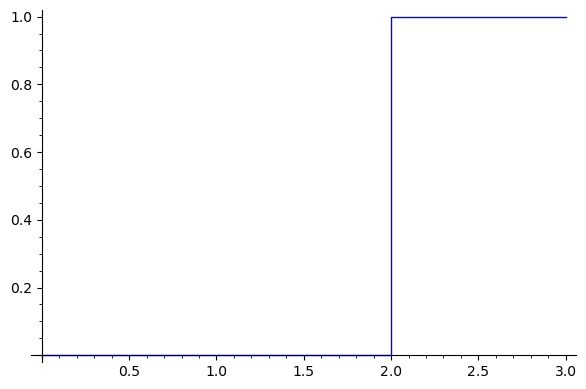

In [3]:
line2d([(0,0),(1,0),(2,0),(2,1),(3,1)]) # correspond au chemin [(1, 0), (1, 0), (0, 1), (1, 0)]

**Compléter la fonction suivante qui prend en paramètre un chemin et retourne le *plot* du chemin avec `ligne2d`.**

**Attention** Le chemin est donné sous forme de *pas*, à vous de calculer les coordonnées des points successifs !

In [4]:
def afficheChemin(chemin):
    """
    Renvoie l'affichage d'un chemin donné par une liste de pas
    INPUT :
        * chemin, uen liste de vecteurs pas
    
    OUTPUT : un objet graphique représentant le chemin
    """
    currentpos = (chemin[0])
    trace = [currentpos]
    for i,dir in enumerate(chemin):
        if i!=0:
            trace.append((trace[-1][0]+dir[0], trace[-1][1]+dir[1]))
    return line2d(trace)


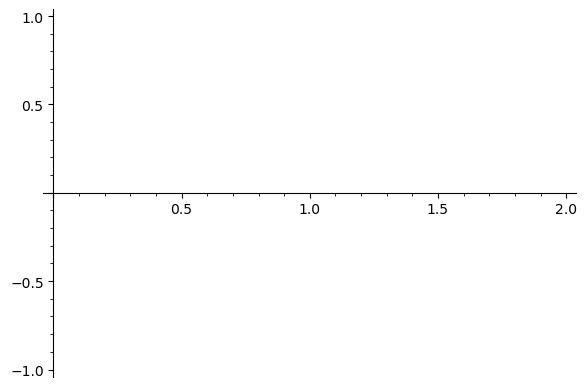

In [5]:
afficheChemin([(1,0)]) # doit afficher un pas unique horizontal

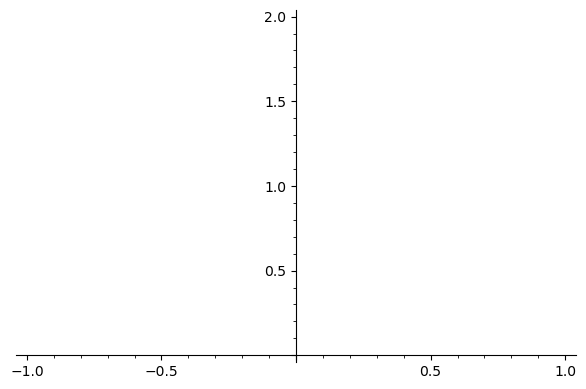

In [6]:
afficheChemin([(0,1)]) # doit afficher un pas unique vertical

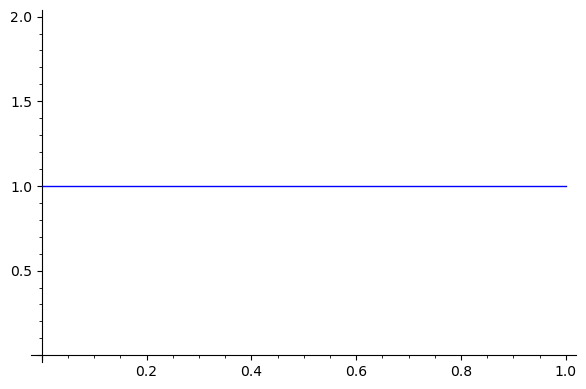

In [7]:
afficheChemin([(0,1), (1,0)]) # doit afficher deux pas : un vertical + un horizontal

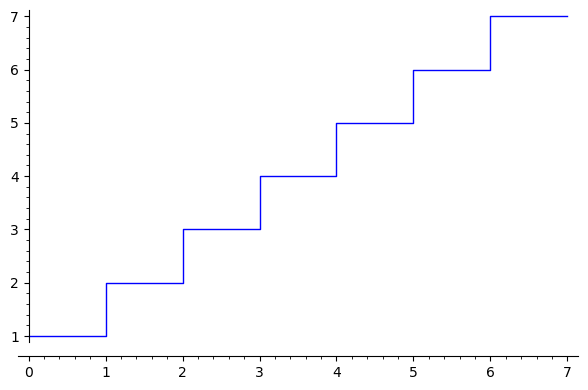

In [8]:
 # doit afficher un escalier
afficheChemin([(0,1), (1,0), (0,1), (1,0), (0,1), (1,0), (0,1), (1,0), (0,1), (1,0), (0,1), (1,0), (0,1), (1,0)])

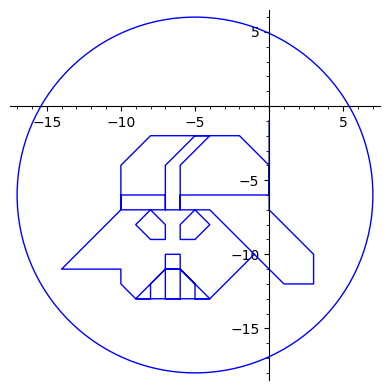

In [9]:
# doit afficher Dark Vador
chemin = [(0,-1), (0,-1), (0, -1), (0,-1), (0,-1), (0,-1), (0,-1), (1,-1), (1,-1), (1,-1), (0,-1), (0,-1), (-1,0), (-1,0), (-1,1), (-1,1), (-1,-1), (-1,-1), (-1,-1), (-1,0), (1,0), (-1,1), (0,-1), (-1,0), (0,1), (0,1), (1,-1), (-1,1),(0,1), (-1,0), (0, -1), (1,0),(-1,0), (0,-1), (0,-1), (1,0), (-1,0), (-1,0), (0,1), (1,1), (-1,-1), (-1, -1), (1, 0), (-1,0), (-1,1), (0,1), (-1,0), (-1,0), (-1,0), (-1,0), (1,1), (1,1), (1,1), (1,1), (0,1), (0,1), (0,1), (1,1), (1,1), (1,0), (1,0), (1,0), (-1, -1), (-1, -1), (0,-1), (0,-1), (-1,0), (-1,0), (-1,0), (0,-1), (1,0), (1,0), (-1,-1), (1,-1), (1,0), (0,1), (-1,1), (1,0), (0,1), (0,-1), (1,0), (0,1), (0,1), (0,1), (1,1), (1,1), (-1,0), (1,0), (1,0), (1,0), (1,-1), (1,-1), (0,-1), (0,-1), (-1,0), (-1,0), (-1,0), (-1,0), (-1,0), (-1,0), (0,-1), (1,0), (-1,-1), (0,-1), (1,0), (1,1), (-1,1), (1,0), (1,-1), (1,-1), (1,-1)]
afficheChemin(chemin) + circle((-5,-6), 12)

## Génération de tous les chemins

On dit qu'un chemin est de *taille $n$* s'il contient exactement $n$ pas. Le but de ce TP est d'écrire une fonction qui fabrique la liste de tous les chemins de taille $n$ en "escalier", c'est-à-dire formés des deux pas : $(1,0)$ et $(0,1)$.

Observez les fonctions suivantes :

In [10]:
def chemins0():
    R = []
    R.append([]) # un chemin de taille 0 est une liste vide
    return R
    
def chemins1():
    R = []
    R.append([(1,0)]) # on ajoute les 2 chemins de taile 1 posible
    R.append([(0,1)])
    return R
    
def chemins2():
    R = []
    for chemin in chemins1():
        chemin_a = list(chemin)  # on copie le chemin
        chemin_a.append((1,0)) # on lui ajoute le pas (1,0)
        chemin_b = list(chemin) # on copie le chemin
        chemin_b.append((0,1)) # on lui ajoute le pas (0,1)
        R.append(chemin_a) # on ajoute les deux chemins  au résultat
        R.append(chemin_b)
    return R

In [11]:
chemins2() # la liste des chemins de taille 2

[[(1, 0), (1, 0)], [(1, 0), (0, 1)], [(0, 1), (1, 0)], [(0, 1), (0, 1)]]

In [12]:
len(chemins2()) # il y en a 4

4

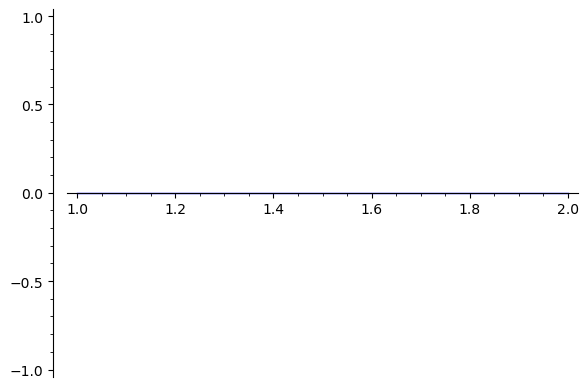

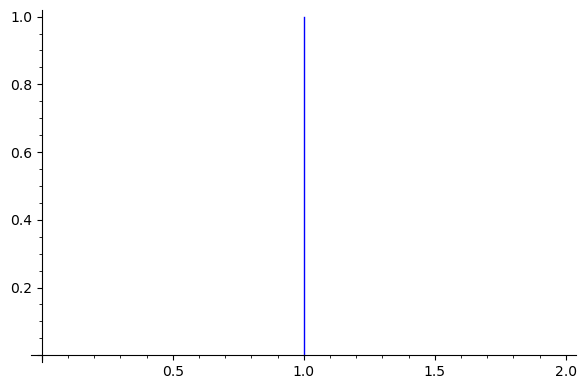

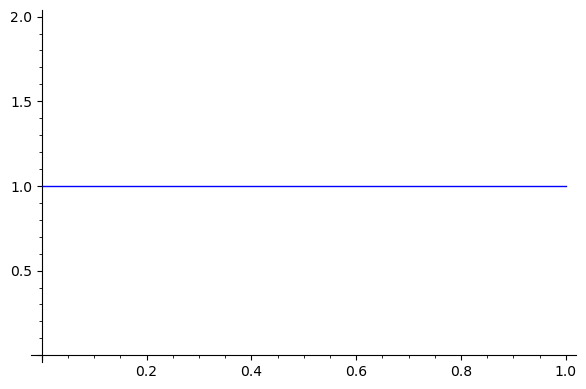

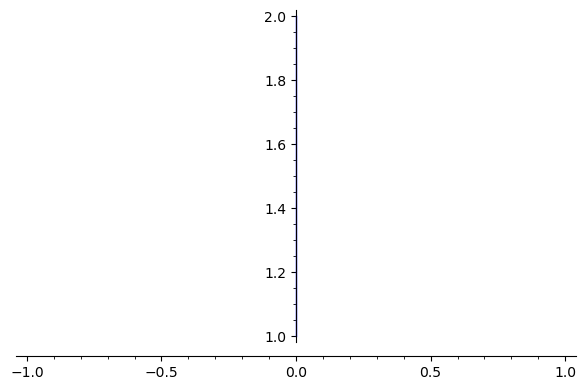

In [13]:
# on peut tous les dessiner
for chemin in chemins2():
    afficheChemin(chemin).show()

**En vous inspirant de la fonction `chemins2`, écrivez une fonction `chemins3` qui renvoie la liste des chemins de taille 3.**

In [14]:
def chemins3():
    """
    Retourne la liste des chemins de taille 3
    """
    R = []
    for chemin in chemins2():
        chemin_a = list(chemin)  # on copie le chemin
        chemin_a.append((1,0)) # on lui ajoute le pas (1,0)
        chemin_b = list(chemin) # on copie le chemin
        chemin_b.append((0,1)) # on lui ajoute le pas (0,1)
        R.append(chemin_a) # on ajoute les deux chemins  au résultat
        R.append(chemin_b)
    return R

In [15]:
chemins3()

[[(1, 0), (1, 0), (1, 0)],
 [(1, 0), (1, 0), (0, 1)],
 [(1, 0), (0, 1), (1, 0)],
 [(1, 0), (0, 1), (0, 1)],
 [(0, 1), (1, 0), (1, 0)],
 [(0, 1), (1, 0), (0, 1)],
 [(0, 1), (0, 1), (1, 0)],
 [(0, 1), (0, 1), (0, 1)]]

In [16]:
# quelques tests que doit valider votre fonction: si tout va bien, rien ne s'affiche !
R = chemins3()
assert(len(R) == 8)
assert([(1,0),(0,1),(0,1)] in R)

**Sur la même idée, écrivez à présent une fonction `chemins` qui prend en paramètre une taille $n$ et renvoie la liste des chemins de taille $n$.**

Indication :

* Votre fonction ne doit *pas* utiliser les fonctions précédentes (`chemins1`, `chemins2` et `chemins3`).
* Pensez à *séparer* le cas $n=0$ des autres cas.

In [17]:
def chemins(n):
    """
    Retourne la liste des chemins de taille n
    """
    chemins = []
    if not n:
        return [[]]
    chemins.append([[(0,1)],[(1,0)]])
    for i in range(n-1):
        R = []
        for chemin in chemins[i]:
            chemin_a = list(chemin)  # on copie le chemin
            chemin_a.append((1,0)) # on lui ajoute le pas (1,0)
            chemin_b = list(chemin) # on copie le chemin
            chemin_b.append((0,1)) # on lui ajoute le pas (0,1)
            R.append(chemin_a) # on ajoute les deux chemins  au résultat
            R.append(chemin_b)
        chemins.append(R)
    return chemins[-1]

In [18]:
chemins(3)

[[(0, 1), (1, 0), (1, 0)],
 [(0, 1), (1, 0), (0, 1)],
 [(0, 1), (0, 1), (1, 0)],
 [(0, 1), (0, 1), (0, 1)],
 [(1, 0), (1, 0), (1, 0)],
 [(1, 0), (1, 0), (0, 1)],
 [(1, 0), (0, 1), (1, 0)],
 [(1, 0), (0, 1), (0, 1)]]

In [19]:
# testons la fonction, d'abord le cas 0
assert(chemins(0) == [[]]) # On doit renvoyer une liste contenant le chemin vide 

In [20]:
# maintenant, les chemins avec un peu plus de pas
assert(len(chemins(1)) == 2)
assert(len(chemins(2)) == 4)
C1 = chemins(3)
C2 = chemins3()
C1.sort()
C2.sort()
assert(C1 == C2)
assert(len(chemins(4)) == 16)

Le but est maintenant de compléter la fonction suivante `chemins_end_point` qui doit renvoyer tous les chemins terminant en un point $(a,b)$ du plan (en commençant à $(0,0)$, toujours en utilisant nos deux pas possible. Par exemple, il y a deux chemins qui terminent au point $(1,1)$ :

* `[(0,1), (1,0)]`
* `[(1,0), (0,1)]`

**Compléter la fonction ci-dessous**. Pour vous aider :

* Pas besoin d'utiliser les fonctions précédentes
* Quelles sont les zones du plan que je ne pourrais jamais atteindre ? Si j'appelle ma fonction sur un point non atteignable, que doit-elle renvoyer ?
* Que doit renvoyer ma fonction si je l'appelle sur $(0,0)$ ? 
* Si je cherche les chemins temrinant en $(a,b)$, où finissait mon chemin juste avant le dernier pas ?

In [21]:
def permutUnique01(nb0,nb1)->list[list] :
    if(nb0 == 0):
        return [nb1*[(1,0)]]
    elif(nb1 == 0):
        return [nb0*[(0,1)]]
    else:
        startsW0 = permutUnique01(nb0-1,nb1)
        startsW0FR = []
        for l in startsW0:
            lcop = l +[]
            startsW0FR.append([(0,1)] + lcop)
        startsW1 = permutUnique01(nb0,nb1-1)
        startsW1FR = []
        for l in startsW1:
            lcop = l + []
            startsW1FR.append([(1,0)] + lcop)
        return startsW0FR + startsW1FR
def chemins_end_point(a,b):
    if(a<0 or b<0):
        raise Exception('point non valide')
    return permutUnique01(b,a)

In [22]:
chemins_end_point(1,1)

[[(0, 1), (1, 0)], [(1, 0), (0, 1)]]

In [24]:
# tout d'abord, testons les conditions limites
assert(chemins_end_point(-1,2) == []) # si a < 0, alors il n'y a aucun chemin (liste vide)

Exception: point non valide

In [25]:
assert(chemins_end_point(2,-2) == []) # si b < 0, alors il n'y a aucun chemin (liste vide)

Exception: point non valide

In [23]:
assert(chemins_end_point(0,0) == [[]]) # si a = b = 0, alors il y a 1 unique chemin dans la liste : le chemin vide

In [24]:
# maintenant, testons les chemins avec 1 seul pas
assert(chemins_end_point(1,0) == [[(1,0)]])
assert(chemins_end_point(0,1) == [[(0,1)]])

In [25]:
# maintenant, testons les chemins avec plusieurs pas
assert(len(chemins_end_point(1,1)) == 2)
assert(len(chemins_end_point(3,5)) == binomial(8,3))

**Vérifier sur plusieurs valeurs de $a$ et $b$ que le nombre de chemins obtenus est égal à `binomial(a+b,a)`.**

In [26]:
assert(len(chemins_end_point(3,45)) == binomial(48,3))

In [27]:
assert(len(chemins_end_point(6,4)) == binomial(10,6))

In [28]:
assert(len(chemins_end_point(0,0)) == binomial(0,0))

On complique encore un peu les choses : **écrivez à présent une fonction `chemins_up_end_point` qui renvoie un générateur sur les chemins terminant en $(a,b)$ et tel qu'en tout point le chemin soit au dessus de la diagonale, c'est à dire qu'on doit toujours avoir $y \geq x$.**

Indication :

* pas besoin d'utiliser les fonctions précédentes
* c'est *presque* la même chose que la fonction précédente, il suffit de rajouter une condition !

In [52]:
def permutUnique01(b,a)->list[list] :
    if(a>b):
        return []
    if(b == 0):
        return [a*[(1,0)]]
    elif(a == 0):
        return [b*[(0,1)]]
    else:
        startsW0 = permutUnique01(b-1,a)
        startsW0FR = []
        for l in startsW0:
            lcop = l +[]
            startsW0FR.append([(0,1)] + lcop)
        startsW1 = permutUnique01(b,a-1)
        startsW1FR = []
        for l in startsW1:
            lcop = l + []
            startsW1FR.append([(1,0)] + lcop)
        return startsW0FR + startsW1FR
def chemins_up_end_point(a,b):
    if(a<0 or b<0):
        raise Exception('point non valide')
    return permutUnique01(b,a)


In [53]:
chemins_up_end_point(1,1)

[[(1, 0), (0, 1)]]

In [54]:
# testons... D'abord les conditions limites
assert(chemins_up_end_point(-1,0) == [])
assert(chemins_up_end_point(0,-1) == [])
assert(chemins_up_end_point(2,1) == []) # comme 1 < 2, il n'y a aucun chemin vérifiant la condition qui termine en (2,1)

Exception: point non valide

In [55]:
# le cas (0,0) qui doit renvoyer le chemin vide
assert(chemins_up_end_point(0,0) == [[]])

In [56]:
# un cas avec un seul chemin et un seul pas
assert(chemins_up_end_point(0,1) == [[(0,1)]])

In [57]:
# des cas un peu plus gros
assert(len(chemins_up_end_point(3,3)) == 5)
assert(len(chemins_up_end_point(4,4)) == 14)

**Selon cette contrainte, combien obtenez-vous de chemins qui terminent en (5,5) ?**

*The Ultimate Question of Life, the Universe and Everything*

In [60]:
len(chemins_up_end_point(5,5))

42

In [34]:
42

**Comptez les chemins qui terminent en $(n,n)$ pour $1 \leq n \leq 6$ et cherchez ces nombres sur Google**

In [62]:
print([len(chemins_up_end_point(n,n)) for n in range(1,7)])

[1, 2, 5, 14, 42, 132]


Les *Nombres de Catalans* sont des objets classiques de la combinatoire. Parcourez [la page wikipedia](https://fr.wikipedia.org/wiki/Nombre_de_Catalan) et voyez si trouvez dans Sage certains des objets décrits.

Aller plus loin : vous pouvez continuer les expériences sur les chemins en faisant varier les pas possibles et contraintes. Lorsque vous obtenez une suite de nombres, vous pouvez regarder sur le site [OEIS](http://oeis.org/) si elle correspond à des objets combinatoires connus. 